# Chapter 18: Triangles Know the Distance

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will find the long side of a right triangle from the two short sides, see why the squares of the legs add, trap a square root that is not a whole number, and catch a triangle that only looks right.

**A note before you start:** the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight down the page like a short chapter. If you are curious, peek at the code, and change a number to see what happens.

## Setup

This cell loads the tools for the calculations and the pictures. Nothing to change here.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, Wedge

INK, TEAL, TERRA, GREY, LIGHT = "#172a3b", "#2f7f79", "#a24a33", "#6b7785", "#d5dbe1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def say(label, text):
    """Print one labeled line of a worked calculation."""
    print(f"{label}: {text}")
import math

## 1. Legs, hypotenuse and the quick check

**Question:** once you know the two legs, how long is the side across from the right angle?

**The equations from the chapter:**

$$a^2+b^2=c^2 \qquad\qquad \max(a, b) < c < a + b$$

**What the symbols mean:** $a$ and $b$ are the legs, the two sides that meet at the right angle. $c$ is the hypotenuse, the slanted side opposite the right angle. $\max(a, b)$ means the larger leg. All lengths are in grid units.

**Predict first:** double both legs from 3 and 4 to 6 and 8. Does the hypotenuse double too?

In [2]:
def right_triangle(a, b):
    c2 = a * a + b * b
    c = math.isqrt(c2)
    assert c * c == c2
    say("Legs", f"{a} and {b}")
    say("Sum of squared legs", f"{a}\u00b2 + {b}\u00b2 = {a*a} + {b*b} = {c2}")
    say("Hypotenuse", f"sqrt({c2}) = {c}")
    say("Two-leg route", f"{a} + {b} = {a + b}")
    say("Magnitude check", f"{max(a, b)} < {c} < {a + b}")
    return c

c = right_triangle(3, 4)
print()
print("Other menu values:")
for a, b in [(6, 8), (9, 12)]:
    right_triangle(a, b)
    print()

Legs: 3 and 4
Sum of squared legs: 3² + 4² = 9 + 16 = 25
Hypotenuse: sqrt(25) = 5
Two-leg route: 3 + 4 = 7
Magnitude check: 4 < 5 < 7

Other menu values:
Legs: 6 and 8
Sum of squared legs: 6² + 8² = 36 + 64 = 100
Hypotenuse: sqrt(100) = 10
Two-leg route: 6 + 8 = 14
Magnitude check: 8 < 10 < 14

Legs: 9 and 12
Sum of squared legs: 9² + 12² = 81 + 144 = 225
Hypotenuse: sqrt(225) = 15
Two-leg route: 9 + 12 = 21
Magnitude check: 12 < 15 < 21



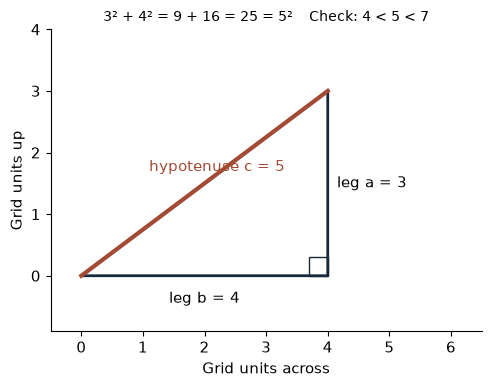

In [3]:
a, b = 3, 4
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([0, b, b, 0], [0, 0, a, 0], color=INK, linewidth=2)
ax.plot([0, b], [0, a], color=TERRA, linewidth=3)
ax.add_patch(Rectangle((b - 0.3, 0), 0.3, 0.3, fill=False, edgecolor=INK))
ax.text(b / 2, -0.25, f"leg b = {b}", ha="center", va="top")
ax.text(b + 0.15, a / 2, f"leg a = {a}", va="center")
ax.text(b / 2 - 0.9, a / 2 + 0.2, f"hypotenuse c = {c}", color=TERRA)
ax.set_xlim(-0.5, 6.5); ax.set_ylim(-0.9, 4)
ax.set_aspect("equal"); ax.set_xlabel("Grid units across"); ax.set_ylabel("Grid units up")
ax.set_title(f"{a}\u00b2 + {b}\u00b2 = {a*a} + {b*b} = {a*a+b*b} = {c}\u00b2    Check: {max(a,b)} < {c} < {a+b}", fontsize=10)
plt.tight_layout(); plt.show()

**What this shows:** square each leg, add, and the hypotenuse is the length whose square matches that sum. The quick check says the answer must beat the longer leg (4) but lose to the walk around the corner (3 + 4 = 7). An answer outside that window is wrong before you even look at decimals. Doubling both legs does double the hypotenuse (5 becomes 10).

**Where it stops working:** you need a flat surface and a right angle where the two legs meet. Without the right angle, the relationship does not apply.

## 2. Four triangles explain the squares

**Question:** why does the rule add the squares of the legs instead of the legs themselves?

**The equation from the chapter:**

$$(a+b)^2=4\left(\frac{ab}{2}\right)+c^2=2ab+c^2.$$

**What the symbols mean:** $a$ and $b$ are the legs of each corner triangle, and $c$ is its hypotenuse. $(a+b)^2$ is the area of the big square. $ab/2$ is the area of one triangle. $c^2$ is the area of the tilted middle square.

**Predict first:** shrink the short leg $a$ from 3 down to 1 while $b$ stays 4. What area is left in the middle? (The table below has all four.)

In [4]:
def four_triangles(a, b):
    n = a + b
    big = n * n
    tri = 4 * a * b // 2
    say("Big square (a + b)\u00b2", f"({a} + {b})\u00b2 = {big}")
    say("Four triangles 2ab", f"4 x {a} x {b} / 2 = {tri}")
    say("Central square c\u00b2", f"{big} - {tri} = {big - tri}")
    say("a\u00b2 + b\u00b2", f"{a*a} + {b*b} = {a*a + b*b}")
    return big - tri

four_triangles(3, 4)
print()
print("Other menu values (a, with b = 4):")
for a in [1, 2, 4]:
    mid = four_triangles(a, 4)
    print()

Big square (a + b)²: (3 + 4)² = 49
Four triangles 2ab: 4 x 3 x 4 / 2 = 24
Central square c²: 49 - 24 = 25
a² + b²: 9 + 16 = 25

Other menu values (a, with b = 4):
Big square (a + b)²: (1 + 4)² = 25
Four triangles 2ab: 4 x 1 x 4 / 2 = 8
Central square c²: 25 - 8 = 17
a² + b²: 1 + 16 = 17

Big square (a + b)²: (2 + 4)² = 36
Four triangles 2ab: 4 x 2 x 4 / 2 = 16
Central square c²: 36 - 16 = 20
a² + b²: 4 + 16 = 20

Big square (a + b)²: (4 + 4)² = 64
Four triangles 2ab: 4 x 4 x 4 / 2 = 32
Central square c²: 64 - 32 = 32
a² + b²: 16 + 16 = 32



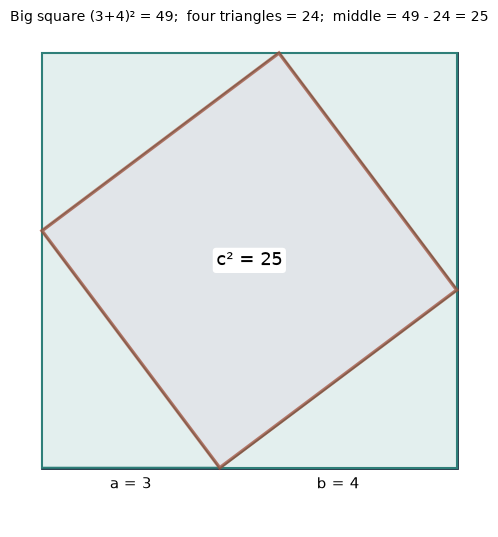

In [5]:
a, b = 3, 4
n = a + b
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(Rectangle((0, 0), n, n, fill=False, edgecolor=INK, linewidth=2))
corners = [[(0, 0), (a, 0), (0, b)], [(a, 0), (n, 0), (n, a)], [(n, a), (n, n), (b, n)], [(b, n), (0, n), (0, b)]]
for pts in corners:
    ax.add_patch(Polygon(pts, closed=True, facecolor="#e3efee", edgecolor=TEAL, linewidth=1.5))
ax.add_patch(Polygon([(a, 0), (n, a), (b, n), (0, b)], closed=True, facecolor=LIGHT, edgecolor=TERRA,
                     linewidth=2.5, alpha=0.7))
ax.text(n / 2, n / 2, f"c\u00b2 = {n*n - 24}", ha="center", va="center", fontsize=13,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none"))
ax.text(a / 2, -0.15, f"a = {a}", ha="center", va="top")
ax.text(a + b / 2, -0.15, f"b = {b}", ha="center", va="top")
ax.set_xlim(-0.4, n + 0.4); ax.set_ylim(-1, n + 0.4); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Big square ({a}+{b})\u00b2 = {n*n};  four triangles = 24;  middle = {n*n} - 24 = {n*n-24}", fontsize=10)
plt.tight_layout(); plt.show()

**What this shows:** count the big square two ways. By its side: $(3 + 4)^2 = 49$. By its pieces: four triangles of area 6 each (24 in all) plus the tilted middle square. What is left over, $49 - 24 = 25$, is $c^2$, and it matches $3^2 + 4^2 = 9 + 16 = 25$. When a formula seems handed down from nowhere, counting one area in two ways is a way to see that it has earned its place.

**Where it stops working:** the four triangles must be identical and right-angled, laid in a flat plane so each outer side is $a + b$. If the triangles were not right, the middle shape would not be a square.

## 3. Trap a square root that is not whole

**Question:** when the squares add to 20, how do you find the length without a calculator?

**The equations from the chapter:**

$$c^2=2^2+4^2=20 \qquad\qquad 4.47^2=19.9809$$

**What the symbols mean:** $c$ is the hypotenuse in meters. $\sqrt{20}$ is the exact length whose square is 20. A bracket is a pair of numbers: one whose square lands below the target and one whose square lands above.

**Predict first:** switch from whole numbers to tenths. Which two tenths trap $\sqrt{20}$?

In [6]:
a, b = 2, 4
n = a * a + b * b
say("c\u00b2 for these legs", f"{a}\u00b2 + {b}\u00b2 = {a*a} + {b*b} = {n}")
say("Exact hypotenuse", f"sqrt({n}) m")
print()
print("Trapping by whole numbers:")
for k in [4, 5]:
    print(f"  {k} x {k} = {k*k}", "(below 20)" if k * k < n else "(above 20)")
say("Bracket (whole numbers)", f"4 < sqrt({n}) < 5")
print()
print("Trapping by tenths:")
for t in [4.4, 4.5]:
    print(f"  {t} x {t} = {t*t:.2f}", "(below 20)" if t * t < n else "(above 20)")
say("Bracket", f"4.4 < sqrt({n}) < 4.5")
say("Nearest hundredth", f"about {math.sqrt(n):.2f} m")
say("Squaring the rounded value back", f"4.47 x 4.47 = {4.47*4.47:.4f}  (close to 20, not exactly 20)")
print()
print("Other menu values:")
for a2, b2 in [(1, 2), (1, 1), (3, 4)]:
    n2 = a2 * a2 + b2 * b2
    r = math.sqrt(n2)
    if r == int(r):
        print(f"  legs {a2} and {b2}: {a2}\u00b2 + {b2}\u00b2 = {n2}, and {int(r)} x {int(r)} = {n2}, so c = {int(r)} exactly (a whole answer)")
    else:
        lo = math.floor(r * 10) / 10
        print(f"  legs {a2} and {b2}: {a2}\u00b2 + {b2}\u00b2 = {n2}; {lo} x {lo} = {lo*lo:.2f} is below, {lo+0.1:.1f} x {lo+0.1:.1f} = {(lo+0.1)**2:.2f} is above; sqrt({n2}) is between {lo} and {lo+0.1:.1f}, about {r:.2f} m")

c² for these legs: 2² + 4² = 4 + 16 = 20
Exact hypotenuse: sqrt(20) m

Trapping by whole numbers:
  4 x 4 = 16 (below 20)
  5 x 5 = 25 (above 20)
Bracket (whole numbers): 4 < sqrt(20) < 5

Trapping by tenths:
  4.4 x 4.4 = 19.36 (below 20)
  4.5 x 4.5 = 20.25 (above 20)
Bracket: 4.4 < sqrt(20) < 4.5
Nearest hundredth: about 4.47 m
Squaring the rounded value back: 4.47 x 4.47 = 19.9809  (close to 20, not exactly 20)

Other menu values:
  legs 1 and 2: 1² + 2² = 5; 2.2 x 2.2 = 4.84 is below, 2.3 x 2.3 = 5.29 is above; sqrt(5) is between 2.2 and 2.3, about 2.24 m
  legs 1 and 1: 1² + 1² = 2; 1.4 x 1.4 = 1.96 is below, 1.5 x 1.5 = 2.25 is above; sqrt(2) is between 1.4 and 1.5, about 1.41 m
  legs 3 and 4: 3² + 4² = 25, and 5 x 5 = 25, so c = 5 exactly (a whole answer)


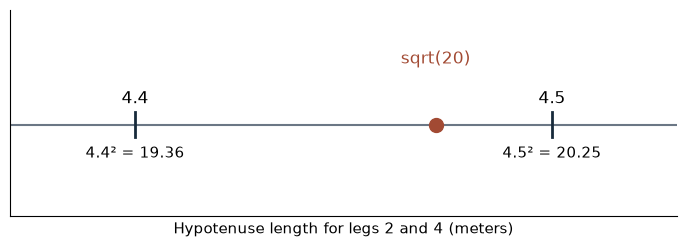

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
lo, hi, root = 4.4, 4.5, math.sqrt(20)
ax.plot([4.37, 4.53], [0, 0], color=GREY, linewidth=1.5)
for v in (lo, hi):
    ax.plot([v, v], [-0.08, 0.08], color=INK, linewidth=2)
    ax.text(v, 0.14, f"{v}", ha="center", fontsize=12)
    ax.text(v, -0.14, f"{v}\u00b2 = {v*v:.2f}", ha="center", va="top")
ax.plot([root], [0], "o", color=TERRA, markersize=10)
ax.text(root, 0.4, "sqrt(20)", ha="center", color=TERRA, fontsize=12)
ax.set_xlim(4.37, 4.53); ax.set_ylim(-0.6, 0.75); ax.set_yticks([]); ax.set_xticks([])
ax.set_xlabel("Hypotenuse length for legs 2 and 4 (meters)")
plt.tight_layout(); plt.show()

**What this shows:** square nearby numbers until one lands below the target and the next lands above. The root is trapped between them, and finer steps shrink the trap. Keep the exact root, $\sqrt{20}$, for later work, and give a rounded decimal only when someone needs a display.

**Where it stops working:** you still need a stated right angle and legs in meters. The decimal 4.47 is rounded, so its square (19.9809) is close to 20 but not equal to it. And when the root is whole, as with legs 3 and 4, the trap closes on the answer itself.

## 4. When the right angle is missing

**Question:** a triangle has sides 4, 5 and 6. Is it a right triangle?

**The equations from the chapter:**

$$4^2 + 5^2 = 16 + 25 = 41 \qquad\qquad 6^2 = 36$$

**What the symbols mean:** the three numbers are given side lengths, with the longest last. Each square is that side times itself. In the picture, a square is built on each side and ruled into unit cells, so you can count them.

**Predict first:** pick sides 3, 4 and 5. Do the two cell counts match this time?

In [8]:
def check_sides(a, b, c):
    left, right = a * a + b * b, c * c
    say("Shorter sides squared", f"{a}\u00b2 + {b}\u00b2 = {a*a} + {b*b} = {left}")
    say("Longest side squared", f"{c}\u00b2 = {right}")
    if left == right:
        say("Comparison", "equal")
        say("Right triangle?", "not ruled out; the right angle must still be given")
    else:
        sign = ">" if left > right else "<"
        say("Comparison", f"unequal ({left} {sign} {right})")
        say("Right triangle?", "no, ruled out")

check_sides(4, 5, 6)
print()
print("Other menu values:")
for s in [(3, 4, 5), (2, 3, 4), (5, 5, 7)]:
    print(f"  sides {s}:")
    check_sides(*s)

Shorter sides squared: 4² + 5² = 16 + 25 = 41
Longest side squared: 6² = 36
Comparison: unequal (41 > 36)
Right triangle?: no, ruled out

Other menu values:
  sides (3, 4, 5):
Shorter sides squared: 3² + 4² = 9 + 16 = 25
Longest side squared: 5² = 25
Comparison: equal
Right triangle?: not ruled out; the right angle must still be given
  sides (2, 3, 4):
Shorter sides squared: 2² + 3² = 4 + 9 = 13
Longest side squared: 4² = 16
Comparison: unequal (13 < 16)
Right triangle?: no, ruled out
  sides (5, 5, 7):
Shorter sides squared: 5² + 5² = 25 + 25 = 50
Longest side squared: 7² = 49
Comparison: unequal (50 > 49)
Right triangle?: no, ruled out


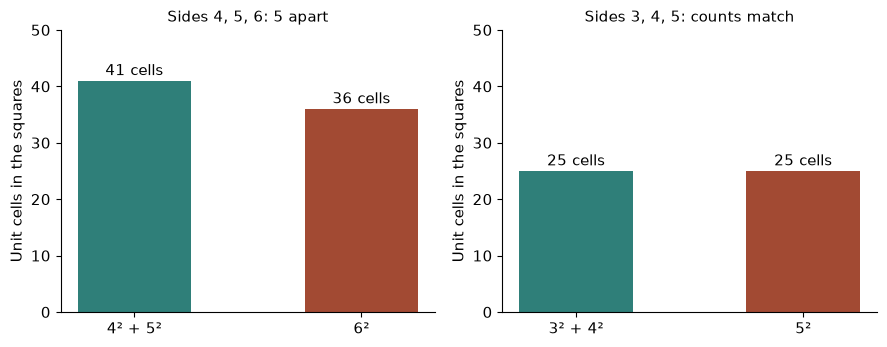

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (a, b, c) in zip(axes, [(4, 5, 6), (3, 4, 5)]):
    left, right = a * a + b * b, c * c
    names = [f"{a}\u00b2 + {b}\u00b2", f"{c}\u00b2"]
    bars = ax.bar(names, [left, right], color=[TEAL, TERRA], width=0.5)
    for rect, val in zip(bars, [left, right]):
        ax.text(rect.get_x() + rect.get_width() / 2, val + 1, f"{val} cells", ha="center")
    ax.set_ylim(0, 50)
    ax.set_title(f"Sides {a}, {b}, {c}: " + ("counts match" if left == right else f"{abs(left-right)} apart"), fontsize=11)
    ax.set_ylabel("Unit cells in the squares")
plt.tight_layout(); plt.show()

**What this shows:** every right triangle must make the cells on the two shorter sides add up to the cells on the longest side. For 4, 5, 6 they do not (41 versus 36), so the triangle is not right, and the given third side stays 6; it is never swapped for $\sqrt{41}$.

**Where it stops working:** unequal counts rule out a right angle. Equal counts, like 3, 4, 5, are not used in this chapter to prove one: the right angle must be stated or marked. Before reaching for the rule, ask where the right angle came from. A drawing that only looks square is not enough.

## Practice

**1.** Legs of 5 and 12: what hypotenuse, and does it pass the quick check?

<details><summary>Show answer</summary>

$5^2 + 12^2 = 25 + 144 = 169$, and $13 \times 13 = 169$, so $c = 13$.
Quick check: $12 < 13 < 5 + 12 = 17$. It passes.

</details>

**2.** With legs 5 and 5, what are the big square, the four triangles, and the middle square?

<details><summary>Show answer</summary>

Big square: $(5 + 5)^2 = 10^2 = 100$.
Four triangles: $4 \times (5 \times 5 / 2) = 4 \times 12.5 = 50$.
Middle square: $100 - 50 = 50$, and $5^2 + 5^2 = 25 + 25 = 50$. They match.

</details>

**3.** Legs of 1 and 3 give $c^2 = 10$. Between which two tenths does $\sqrt{10}$ lie? Then: is a triangle with sides 6, 7 and 9 a right triangle?

<details><summary>Show answer</summary>

$1^2 + 3^2 = 1 + 9 = 10$. Try $3.1 \times 3.1 = 9.61$ (below 10) and $3.2 \times 3.2 = 10.24$ (above 10), so $\sqrt{10}$ is between 3.1 and 3.2.

For sides 6, 7, 9: $6^2 + 7^2 = 36 + 49 = 85$ and $9^2 = 81$. Since 85 is not 81, it is not a right triangle.

</details>